In [1]:
# Task 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Task 2: Load Dataset

df = pd.read_csv("/content/deceptive-opinion.csv")

print("Dataset loaded successfully!")
print("Dataset Name: Deceptive Opinion Spam / Fake Hotel Reviews")
print("Number of Records:", len(df))
print("Number of Columns:", len(df.columns))

Dataset loaded successfully!
Dataset Name: Deceptive Opinion Spam / Fake Hotel Reviews
Number of Records: 1600
Number of Columns: 5


In [3]:
# Task 3: Display Dataset Information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape:
(1600, 5)

Column Names:
['deceptive', 'hotel', 'polarity', 'source', 'text']

First 5 Records:


,deceptive,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...
3,truthful,omni,positive,TripAdvisor,The Omni Chicago really delivers on all fronts...
4,truthful,hyatt,positive,TripAdvisor,I asked for a high floor away from the elevato...


In [4]:
# Task 4: Basic Dataset Check

print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Missing Values:
deceptive    0
hotel        0
polarity     0
source       0
text         0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   deceptive  1600 non-null   object
 1   hotel      1600 non-null   object
 2   polarity   1600 non-null   object
 3   source     1600 non-null   object
 4   text       1600 non-null   object
dtypes: object(5)
memory usage: 62.6+ KB


In [5]:
# Task 5: Check Target Variable

print("Target Variable: deceptive")
print("\nUnique Values:")
print(df["deceptive"].unique())

print("\nValue Counts:")
print(df["deceptive"].value_counts())

Target Variable: deceptive

Unique Values:
['truthful' 'deceptive']

Value Counts:
deceptive
truthful     800
deceptive    800
Name: count, dtype: int64


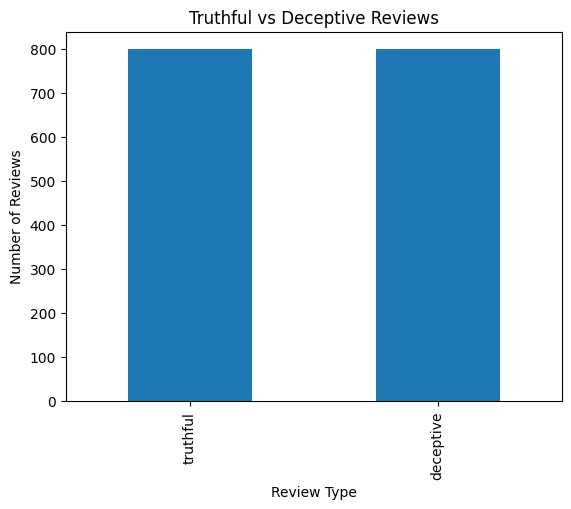

In [6]:
# Task 6: Visualize Target Classes

df["deceptive"].value_counts().plot(kind="bar")

plt.title("Truthful vs Deceptive Reviews")
plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")
plt.show()

In [7]:
# Task 7: Select Features and Target

X = df["text"]
y = df["deceptive"]

print("Feature (X): Review Text")
print("Target (y): Deceptive")

print("\nNumber of Reviews:", len(X))
print("Number of Labels:", len(y))

Feature (X): Review Text
Target (y): Deceptive

Number of Reviews: 1600
Number of Labels: 1600


In [8]:
# Task 8: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))

Training Reviews: 1280
Testing Reviews: 320


In [9]:
# Task 9: Create TF-IDF Vectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

print("TF-IDF Vectorizer created successfully!")

TF-IDF Vectorizer created successfully!


In [10]:
# Task 10: Convert Training Reviews into Numerical Features

X_train_tfidf = tfidf.fit_transform(X_train)

print("Training data converted successfully!")
print("Training Data Shape:", X_train_tfidf.shape)

Training data converted successfully!
Training Data Shape: (1280, 5000)


In [11]:
# Task 11: Convert Testing Reviews into Numerical Features

X_test_tfidf = tfidf.transform(X_test)

print("Testing data converted successfully!")
print("Testing Data Shape:", X_test_tfidf.shape)

Testing data converted successfully!
Testing Data Shape: (320, 5000)


In [12]:
# Task 12: Train Logistic Regression Model

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Task 13: Make Predictions

y_pred = model.predict(X_test_tfidf)

print("Predictions completed successfully!")
print("First 10 Predictions:")
print(y_pred[:10])

Predictions completed successfully!
First 10 Predictions:
['truthful' 'deceptive' 'truthful' 'deceptive' 'truthful' 'deceptive'
 'deceptive' 'truthful' 'deceptive' 'deceptive']


In [14]:
# Task 14: Calculate Model Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.884375
Model Accuracy Percentage: 88.4375 %


In [15]:
# Task 15: Classification Report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

   deceptive       0.89      0.88      0.88       160
    truthful       0.88      0.89      0.89       160

    accuracy                           0.88       320
   macro avg       0.88      0.88      0.88       320
weighted avg       0.88      0.88      0.88       320



Confusion Matrix:
[[140  20]
 [ 17 143]]


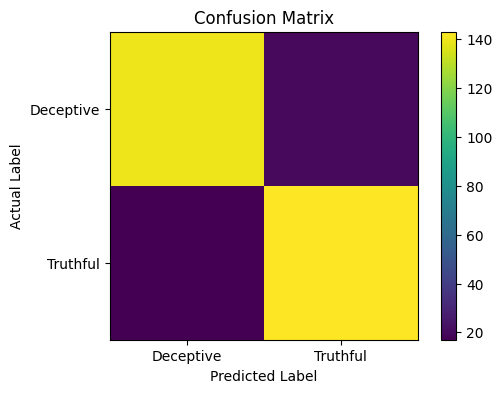

In [16]:
# Task 16: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Deceptive", "Truthful"])
plt.yticks([0, 1], ["Deceptive", "Truthful"])

plt.colorbar()
plt.show()

In [17]:
# Task 17: Create Review Prediction Function

def predict_review(review):
    review_tfidf = tfidf.transform([review])
    prediction = model.predict(review_tfidf)[0]

    return prediction

print("Prediction function created successfully!")

Prediction function created successfully!


In [18]:
# Task 18: Test a Truthful Review

review = "The hotel room was clean and comfortable. The staff were friendly and helpful."

prediction = predict_review(review)

print("Review:")
print(review)

print("\nPrediction:", prediction)

Review:
The hotel room was clean and comfortable. The staff were friendly and helpful.

Prediction: truthful


In [19]:
# Task 19: Test a Deceptive Review

review = "This is the most amazing hotel ever! Everything was absolutely perfect and unbelievably wonderful!"

prediction = predict_review(review)

print("Review:")
print(review)

print("\nPrediction:", prediction)

Review:
This is the most amazing hotel ever! Everything was absolutely perfect and unbelievably wonderful!

Prediction: deceptive


In [20]:
# Task 20: User-Friendly Prediction

def check_review(review):
    review_tfidf = tfidf.transform([review])
    prediction = model.predict(review_tfidf)[0]

    if prediction == "deceptive":
        result = "Deceptive Review"
    else:
        result = "Truthful Review"

    print("Review:")
    print(review)
    print("\nAI Prediction:", result)


check_review("The room was clean, the staff were polite, and my stay was comfortable.")

Review:
The room was clean, the staff were polite, and my stay was comfortable.

AI Prediction: Deceptive Review


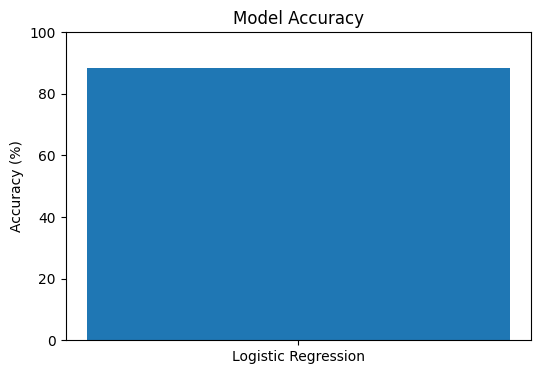

Final Model Accuracy: 88.44 %


In [21]:
# Task 21: Accuracy Visualization

accuracy_percentage = accuracy * 100

plt.figure(figsize=(6, 4))
plt.bar(["Logistic Regression"], [accuracy_percentage])

plt.title("Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

print("Final Model Accuracy:", round(accuracy_percentage, 2), "%")

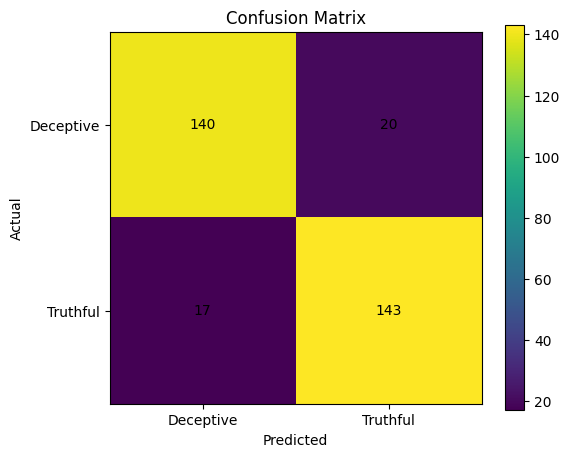

In [22]:
# Task 22: Confusion Matrix Visualization

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Deceptive", "Truthful"])
plt.yticks([0, 1], ["Deceptive", "Truthful"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [23]:
# Task 23: Actual vs Predicted Values

comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

display(comparison)

,Actual,Predicted
0,truthful,truthful
1,truthful,deceptive
2,truthful,truthful
3,deceptive,deceptive
4,truthful,truthful
5,deceptive,deceptive
6,deceptive,deceptive
7,deceptive,truthful
8,deceptive,deceptive
9,deceptive,deceptive


In [24]:
# Task 24: Final Model Performance

report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

performance = pd.DataFrame(report).transpose()

display(performance)

,precision,recall,f1-score,support
deceptive,0.891720,0.875000,0.883281,160.000000
truthful,0.877301,0.893750,0.885449,160.000000
accuracy,0.884375,0.884375,0.884375,0.884375
macro avg,0.884510,0.884375,0.884365,320.000000
weighted avg,0.884510,0.884375,0.884365,320.000000
